# Competition project — House Prices. Fedor Sukhoi

This is the Kaggle *House Prices: Advanced Regression Techniques* set:
- train.csv — 1460 houses with SalePrice
- test.csv — 1459 houses without SalePrice
- data_description.txt — meaning of each field, including when NA means *the feature is absent*

In [ ]:
# setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# pandas good stuff for editing
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")


### The 9-part vacuuming

1) Loading

NA in the raw files often means *none* (no pool, no alley, no garage), not anything actually unknown. 


In [ ]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

# I'll use these two quite a bit up to the end
TARGET = "SalePrice" 
ID_COL = "Id"

print("Training:", train.shape)
print("Test:", test.shape)

train.head()

Training: (1460, 81)
Test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


1460 training rows, 81 columns (including Id and SalePrice). The test file has the same predictors and no target. No duplicate feature rows in train, and Id is unique.


In [ ]:
# Making sure the Id is a unique id
print("Duplicate rows in train (ignoring Id):", train.drop(columns=ID_COL).duplicated().sum())
print("Unique Id, train / test:", train[ID_COL].nunique(), "/", test[ID_COL].nunique())
print("dtype counts:\n", train.dtypes.value_counts())

Duplicate rows in train (ignoring Id): 0
Unique Id, train / test: 1460 / 1459
dtype counts:
 object     43
int64      35
float64     3
Name: count, dtype: int64


2. What Features do I have? Do all of them make sense?

The predictors fall into a few groups. MSSubClass looks numeric but it is some kind of a code, so it should be treated as categorical. OverallQual / OverallCond are ordinal ratings 1–10.

| Group | Columns | Role for SalePrice |
|---|---|---|
| Size | GrLivArea, 1stFlrSF, 2ndFlrSF, TotalBsmtSF, LotArea, LotFrontage, garage/porch/pool areas | More area - more money to pay |
| Quality / condition | OverallQual, OverallCond, ExterQual, KitchenQual, BsmtQual, HeatingQC, GarageQual, ... | OverallQual might be the most descriptive, but more nuanced details can also provide insights |
| Age | YearBuilt, YearRemodAdd, GarageYrBlt, YrSold, MoSold | Newer / recently remodelled houses sell higher |
| Location | Neighborhood, MSZoning, Condition1, Condition2 | Neighbourhood captures a lot of location value |
| Amenities | fireplaces, garage type/finish, basement finish, CentralAir, Functional | Presence or abscence matters |
| Sale context | SaleType, SaleCondition | New / partial sales behave differently |
| Rare extras | PoolQC, MiscFeature, Alley, Fence, Utilities, Street | Mostly constant or almost always absent |

Id is only an index for the final submission. It will reappear only then


In [209]:
numeric_cols = train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = train.select_dtypes(include="object").columns.tolist()

print(numeric_cols)
print()
print(categorical_cols)

['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'Gar

3. Target: SalePrice


In [ ]:
y = train[TARGET].copy()

print(y.describe())
print("skew (raw):", y.skew().round(3)) # positive for right skew, vice versa for left
print("skew (log1p):", np.log1p(y).skew().round(3))

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64
skew (raw): 1.883
skew (log1p): 0.121


Sale prices are right-skewed: a long tail of expensive houses. For linear models predicting log1p(SalePrice) is the best solution and converting back afterwards. Tree models can use the raw price, but the log scale in general is still useful for analysing correlation between features and price, for example.

The competition metric is also RMSE on log prices, so working in log space.

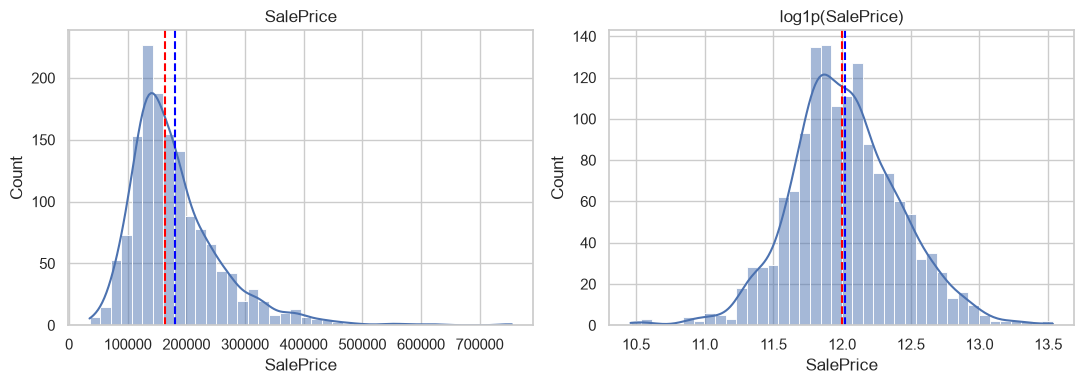

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# basic seaborn plots within a matplotlib fig, axes setup for side-by-side comparison
sns.histplot(y, bins=40, ax=axes[0], kde=True)
axes[0].set_title("SalePrice")
axes[0].axvline(y.median(), color="red", linestyle="--")
axes[0].axvline(y.mean(), color="blue", linestyle="--")

sns.histplot(np.log1p(y), bins=40, ax=axes[1], kde=True)
axes[1].set_title("log1p(SalePrice)")
axes[1].axvline(np.log1p(y).median(), color="red", linestyle="--")
axes[1].axvline(np.log1p(y).mean(), color="blue", linestyle="--")

plt.tight_layout()
plt.show()


Median price is $163k, mean $181k — the tail pulls the mean up. After log1p the distribution is almost symmetric, perfect for a linear or regularized model.


In [ ]:
corr = train.corr(numeric_only=True)[TARGET].sort_values(ascending=False)
print("Numeric correlation with SalePrice:")
corr

Numeric correlation with SalePrice:


SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

OverallQual and GrLivArea dominate. Garage size, basement size, first-floor area, bathrooms, and year built follow. Id, MoSold, and YrSold are essentially uncorrelated with price — month/year of sale may still matter as a weak seasonal effect, but Id can go. Nothing jumps out as unexpected.

There are strong positive correlations, but pretty much no meaningful negative ones.

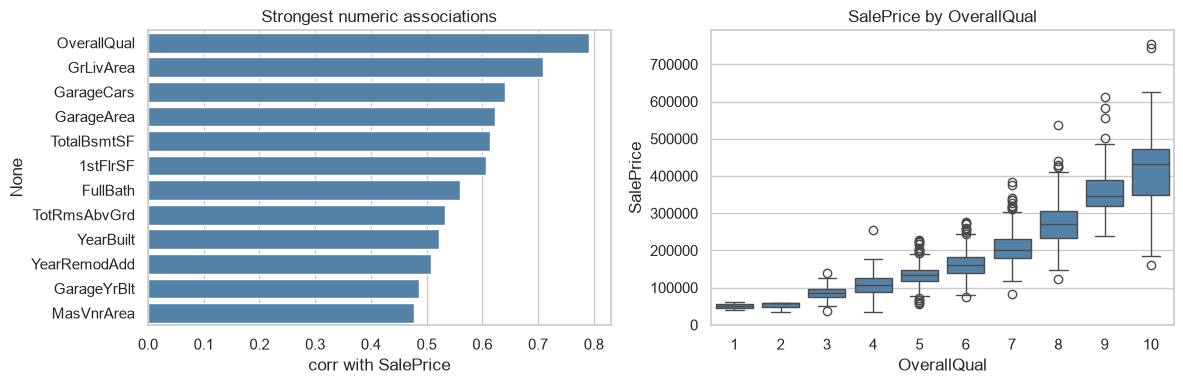

In [ ]:
top = corr.drop(TARGET).head(12) # best correlations, apart from self-correlation

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x=top.values, y=top.index, ax=axes[0], color="steelblue")
axes[0].set_xlabel("corr with SalePrice")
axes[0].set_title("Strongest numeric associations")

# What's the relationship between OverallQual, the most descriptive feature, and SalePrice?
# Are there outliers that bring the correlation down?
sns.boxplot(data=train, x="OverallQual", y=TARGET, ax=axes[1], color="steelblue")
axes[1].set_title("SalePrice by OverallQual")

plt.tight_layout()
plt.show()


I've plotted the relationship between SalePrice and OverallQual with boxplots, because it's telling a very important thing about why the correlation is at 70%, not 100%. There is a very small variance in price for houses with poor condition, but there is a much larger variance as Quality increases. A relatively cheap house can be in great condition, if it's small. The most expensive houses are also outliers here.


4. What do the training features look like?

I've looked at the numerical features to see how different their scales are and how often they are zero. For categorical features, I'm checking which values are rare and which ones have a meaningful order. Missing values come in the next section.


In [ ]:
train.describe().T.head(20)

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [ ]:
zero_share = (train[numeric_cols] == 0).mean().sort_values(ascending=False)
zero_share[zero_share > 0.3]

PoolArea         0.995205
3SsnPorch        0.983562
LowQualFinSF     0.982192
MiscVal          0.964384
BsmtHalfBath     0.943836
ScreenPorch      0.920548
BsmtFinSF2       0.885616
EnclosedPorch    0.857534
HalfBath         0.625342
MasVnrArea       0.589726
BsmtFullBath     0.586301
2ndFlrSF         0.567808
WoodDeckSF       0.521233
Fireplaces       0.472603
OpenPorchSF      0.449315
BsmtFinSF1       0.319863
dtype: float64

Many area features are mostly zero (PoolArea, 3SsnPorch, LowQualFinSF, MiscVal, ...). This makes sense, most houses don't have a pool or a three-season porch. For a linear model, a separate feature saying whether the house has a pool might help. A tree can already split on zero.


In [ ]:
print("MSSubClass codes:", sorted(train["MSSubClass"].unique()))
print("Neighborhoods:", train["Neighborhood"].nunique())
print()
print(train["Neighborhood"].value_counts().head(4))
print()
# How do categorical features' breakdown look like?
print("Quality-style categoricals:")
for col in ["ExterQual", "KitchenQual", "BsmtQual", "HeatingQC", "GarageFinish", "CentralAir"]:
    print(col, "->", dict(train[col].value_counts(dropna=False)))

MSSubClass codes: [np.int64(20), np.int64(30), np.int64(40), np.int64(45), np.int64(50), np.int64(60), np.int64(70), np.int64(75), np.int64(80), np.int64(85), np.int64(90), np.int64(120), np.int64(160), np.int64(180), np.int64(190)]
Neighborhoods: 25

Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Name: count, dtype: int64

Quality-style categoricals:
ExterQual -> {'TA': np.int64(906), 'Gd': np.int64(488), 'Ex': np.int64(52), 'Fa': np.int64(14)}
KitchenQual -> {'TA': np.int64(735), 'Gd': np.int64(586), 'Ex': np.int64(100), 'Fa': np.int64(39)}
BsmtQual -> {'TA': np.int64(649), 'Gd': np.int64(618), 'Ex': np.int64(121), nan: np.int64(37), 'Fa': np.int64(35)}
HeatingQC -> {'Ex': np.int64(741), 'TA': np.int64(428), 'Gd': np.int64(241), 'Fa': np.int64(49), 'Po': np.int64(1)}
GarageFinish -> {'Unf': np.int64(605), 'RFn': np.int64(422), 'Fin': np.int64(352), nan: np.int64(81)}
CentralAir -> {'Y': np.int64(1365), 'N': np.int64(95)}


The quality features use the same ordinal ratings: Ex > Gd > TA > Fa > Po. There is a clear order here, so I can map them to numbers later. Neighborhood and MSZoning don't have this kind of order, should stay categorical.


5. Which columns have missing values?

I've checked both train and test. Some columns only have missing values in test, but the filling rules still need to cover them, since I'll apply the same preprocessing to both files, but separately, looking after potential data leakages.


In [ ]:
def missing_table(df, name): # a function to use on both train and test
    n = df.isna().sum()
    n = n[n > 0].sort_values(ascending=False)
    out = pd.DataFrame({
        "n_missing": n,
        "pct": (n / len(df) * 100).round(2),
        "dtype": df.dtypes.loc[n.index].astype(str),
    })
    print(f"{name}: {len(out)} columns with NaN, {int(n.sum())} missing cells")
    return out


missing_train = missing_table(train, "train")
missing_train

train: 19 columns with NaN, 7829 missing cells


,n_missing,pct,dtype
PoolQC,1453,99.52,object
MiscFeature,1406,96.30,object
Alley,1369,93.77,object
Fence,1179,80.75,object
MasVnrType,872,59.73,object
FireplaceQu,690,47.26,object
LotFrontage,259,17.74,float64
GarageType,81,5.55,object
GarageYrBlt,81,5.55,float64
GarageFinish,81,5.55,object


In [218]:
missing_test = missing_table(test, "test")
missing_test

test: 33 columns with NaN, 7878 missing cells


,n_missing,pct,dtype
PoolQC,1456,99.79,object
MiscFeature,1408,96.50,object
Alley,1352,92.67,object
Fence,1169,80.12,object
MasVnrType,894,61.27,object
FireplaceQu,730,50.03,object
LotFrontage,227,15.56,float64
GarageCond,78,5.35,object
GarageYrBlt,78,5.35,float64
GarageQual,78,5.35,object


NaN only in train: ['Electrical']
NaN only in test: ['BsmtFinSF1', 'BsmtFinSF2', 'BsmtFullBath', 'BsmtHalfBath', 'BsmtUnfSF', 'Exterior1st', 'Exterior2nd', 'Functional', 'GarageArea', 'GarageCars', 'KitchenQual', 'MSZoning', 'SaleType', 'TotalBsmtSF', 'Utilities']


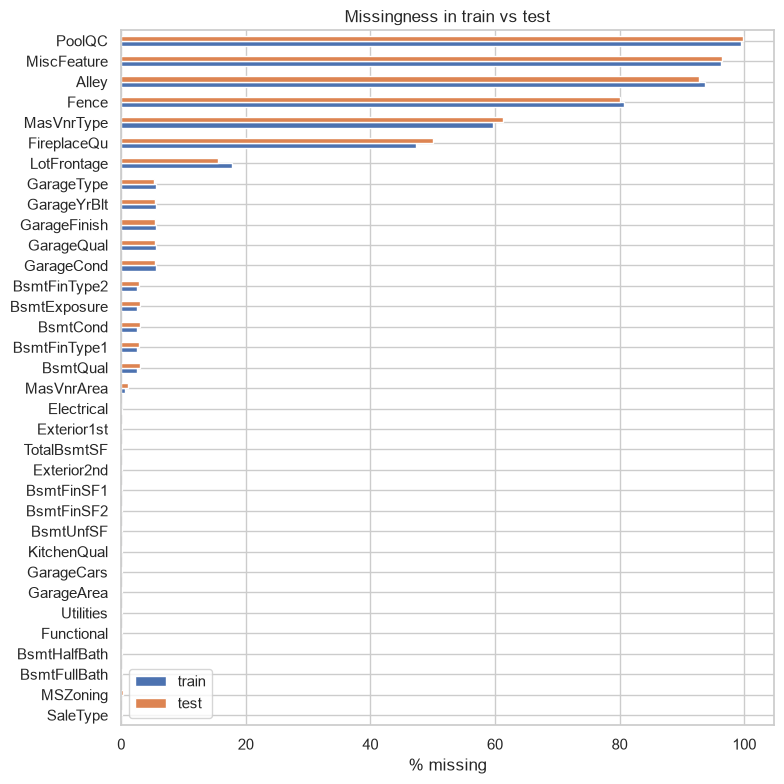

In [ ]:
print("NaN only in train:", sorted(set(missing_train.index) - set(missing_test.index)))
print("NaN only in test:", sorted(set(missing_test.index) - set(missing_train.index)))

# What are the main features with missing values, does that change for train/test?
fig, ax = plt.subplots(figsize=(8, 8))
both = (
    pd.concat(
        [
            missing_train["pct"].rename("train"),
            missing_test["pct"].rename("test"),
        ],
        axis=1,
    )
    .fillna(0)
    .sort_values("train", ascending=True)
)
both.plot(kind="barh", ax=ax)
ax.set_xlabel("% missing")
ax.set_title("Missingness in train vs test")
plt.tight_layout()
plt.show()


There are 19 columns with missing values in train. Test has 33 such columns. 

However, a lot of these values aren't actually unknown. FireplaceQu is missing for exactly the 690 houses with no fireplaces. PoolQC matches houses with no pool, and the garage labels match houses with no garage.

In [ ]:
# If a house has no fireplace, how can it have a ranking of the quality of one?
print("Fireplaces == 0:", (train["Fireplaces"] == 0).sum(), "| FireplaceQu NaN:", train["FireplaceQu"].isna().sum())
print("PoolArea == 0:", (train["PoolArea"] == 0).sum(), "| PoolQC NaN:", train["PoolQC"].isna().sum())
print("GarageCars == 0:", (train["GarageCars"] == 0).sum(), "| GarageType NaN:", train["GarageType"].isna().sum())
print("TotalBsmtSF == 0:", (train["TotalBsmtSF"] == 0).sum(), "| BsmtQual NaN:", train["BsmtQual"].isna().sum())

print()

# If TotalBsmtSF > 0, then there should be a basement category. It's not the case for a few rows
print("Basement category missing while TotalBsmtSF > 0:")
bsmt_cat = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
print(train.loc[train[bsmt_cat].isna().any(axis=1) & (train["TotalBsmtSF"] > 0), ["Id"] + bsmt_cat + ["TotalBsmtSF"]])

print()
print("Electrical missing row:")
print(train.loc[train["Electrical"].isna(), ["Id", "Electrical", "YearBuilt", "Neighborhood", TARGET]])


Fireplaces == 0: 690 | FireplaceQu NaN: 690
PoolArea == 0: 1453 | PoolQC NaN: 1453
GarageCars == 0: 81 | GarageType NaN: 81
TotalBsmtSF == 0: 37 | BsmtQual NaN: 37

Basement category missing while TotalBsmtSF > 0:
      Id BsmtQual BsmtCond BsmtExposure BsmtFinType1 BsmtFinType2  TotalBsmtSF
332  333       Gd       TA           No          GLQ          NaN         3206
948  949       Gd       TA          NaN          Unf          Unf          936

Electrical missing row:
        Id Electrical  YearBuilt Neighborhood  SalePrice
1379  1380        NaN       2006       Timber     167500


Two houses in train have a basement, but one of the labels is missing: Id 333 has no BsmtFinType2, and Id 949 has no BsmtExposure. Actual missing labels here one can't call a 'no-basement' place. 

Electrical has one missing value, for a house built in 2006 in Timber. Another quite rare, but missing record.

6. How should I fill the missing values?

The reason for the missing value matters. If a house has no garage, there is no garage quality to record. If it has a garage but the quality is missing, that's a different problem. Any medians or modes should come from train only.

When the feature is absent, I'll use "None" for a category and 0 for a number:

| Columns | Fill | Why |
|---|---|---|
| Alley, Fence, MiscFeature, PoolQC | "None" | NA means the house doesn't have this feature |
| FireplaceQu | "None" | These houses have no fireplaces |
| GarageType, GarageFinish, GarageQual, GarageCond | "None" if there is no garage | No garage means no quality or finish to record |
| GarageYrBlt | YearBuilt if there is no garage | There is no year to record, so filling with the house's year of construction |
| GarageCars, GarageArea | 0 if there is no garage | Test also has a row with all garage sizes missing |
| BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2 | "None" if there is no basement | These labels don't apply without a basement |
| BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, BsmtFullBath, BsmtHalfBath | 0 if there is no basement | No basement means no area or basement bathrooms |
| MasVnrType | "None" if there is no veneer | Pandas also reads the actual "None" category as missing |
| MasVnrArea | 0 | Treat missing area as no veneer |

For LotFrontage, I'll use the median from the same Neighborhood in train, with the overall train median as a fallback. Houses in the same neighbourhood should have more similar frontage than houses across the whole city.

For values that are actually unknown:

| Columns | Fill | Why |
|---|---|---|
| Electrical | Train mode, SBrkr | Only one missing value |
| MSZoning | Mode within Neighborhood in train | Zoning depends on location |
| KitchenQual, SaleType, Exterior1st, Exterior2nd, Utilities | Train mode | Only one or two missing values in test |
| Functional | "Typ" | The description says to assume typical unless a deduction is recorded |
| Missing basement labels when TotalBsmtSF > 0 | Mode among train houses with a basement | The basement exists, so "None" would be wrong |
| Missing garage features when GarageType is present | Mode / median among train garages of that type | Test houses 2127 and 2577 have detached garages, but some details are missing |
| Missing MasVnrType when MasVnrArea > 0 | Mode among train houses with veneer, BrkFace | There is veneer area, so there should also be a type |

Utilities is AllPub for all but one training house. Filling with AllPub makes sense for now, but the feature might not be useful for the model since it barely varies.


7. Filling the missing values

I'll calculate the medians and modes on train, then use the same values to fill both train and test.


In [221]:
# Filling categories
NONE_LEVEL_COLS = [
    "Alley",
    "Fence",
    "MiscFeature",
    "PoolQC",
    "FireplaceQu",
    "MasVnrType",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
]
BSMT_NUM_COLS = [
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "BsmtFullBath",
    "BsmtHalfBath",
]
BSMT_CAT_COLS = [
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
]
GARAGE_CAT_COLS = ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]


def _mode(series): # a helper function to get the mode of a series, returning NaN if empty
    modes = series.dropna().mode()
    return modes.iloc[0] if len(modes) else np.nan


def fit_imputation(train_df): # calculates medians and modes from training data and stores them in a dictionary
    stats = {}
    stats["lotfrontage_by_neighborhood"] = train_df.groupby("Neighborhood")["LotFrontage"].median() # a separate median for each neighbourhood
    stats["lotfrontage_global"] = train_df["LotFrontage"].median() # the median frontage across train
    stats["electrical"] = _mode(train_df["Electrical"])
    stats["mszoning_by_neighborhood"] = train_df.groupby("Neighborhood")["MSZoning"].agg(_mode)
    stats["mszoning_global"] = _mode(train_df["MSZoning"])
    stats["kitchenqual"] = _mode(train_df["KitchenQual"])
    stats["saletype"] = _mode(train_df["SaleType"])
    stats["exterior1st"] = _mode(train_df["Exterior1st"])
    stats["exterior2nd"] = _mode(train_df["Exterior2nd"])
    stats["utilities"] = _mode(train_df["Utilities"])
    stats["functional"] = "Typ" # default value for functional

    has_bsmt = train_df["TotalBsmtSF"] > 0
    stats["bsmt_cat_mode"] = {c: _mode(train_df.loc[has_bsmt, c]) for c in BSMT_CAT_COLS}

    has_veneer = train_df["MasVnrArea"].fillna(0) > 0
    stats["masvnr_type_when_area"] = _mode(train_df.loc[has_veneer, "MasVnrType"])

    has_garage = train_df["GarageCars"].fillna(0) > 0
    stats["garage_cat_mode"] = {c: _mode(train_df.loc[has_garage, c]) for c in ["GarageFinish", "GarageQual", "GarageCond"]}
    stats["garage_cars_median"] = train_df.loc[has_garage, "GarageCars"].median()
    stats["garage_area_median"] = train_df.loc[has_garage, "GarageArea"].median()
    return stats


def apply_imputation(df, stats): # uses the stats dictionary to fill missing values in whichever dataset you pass in
    out = df.copy()

    # Lot frontage: neighbourhood median, then global train median
    mapped = out["Neighborhood"].map(stats["lotfrontage_by_neighborhood"])
    out["LotFrontage"] = out["LotFrontage"].fillna(mapped).fillna(stats["lotfrontage_global"])

    # Masonry: absence vs a few rows with area but no type
    veneer_area_missing = out["MasVnrArea"].isna()
    out.loc[veneer_area_missing, "MasVnrArea"] = 0
    out.loc[out["MasVnrArea"] == 0, "MasVnrType"] = out.loc[out["MasVnrArea"] == 0, "MasVnrType"].fillna("None")
    out["MasVnrType"] = out["MasVnrType"].fillna(stats["masvnr_type_when_area"])

    # Basement numeric first, so "no basement" is well-defined
    no_bsmt_hint = out["BsmtQual"].isna() & out["BsmtCond"].isna() & out["BsmtFinType1"].isna()
    for col in BSMT_NUM_COLS:
        if col in out.columns:
            out.loc[no_bsmt_hint, col] = out.loc[no_bsmt_hint, col].fillna(0)
            out[col] = out[col].fillna(0)

    no_bsmt = out["TotalBsmtSF"].fillna(0) == 0
    for col in BSMT_CAT_COLS:
        out.loc[no_bsmt, col] = out.loc[no_bsmt, col].fillna("None")
        out[col] = out[col].fillna(stats["bsmt_cat_mode"][col])

    # Garage: absent vs type present but size/finish blank
    garage_type_missing = out["GarageType"].isna()
    for col in ["GarageFinish", "GarageQual", "GarageCond"]:
        out.loc[garage_type_missing, col] = out.loc[garage_type_missing, col].fillna("None")
    if "GarageCars" in out.columns:
        out.loc[garage_type_missing, "GarageCars"] = out.loc[garage_type_missing, "GarageCars"].fillna(0)
    if "GarageArea" in out.columns:
        out.loc[garage_type_missing, "GarageArea"] = out.loc[garage_type_missing, "GarageArea"].fillna(0)

    has_garage_type = out["GarageType"].notna() & (out["GarageType"] != "None")
    for col in ["GarageFinish", "GarageQual", "GarageCond"]:
        out.loc[has_garage_type, col] = out.loc[has_garage_type, col].fillna(stats["garage_cat_mode"][col])
    # Use the house year as a placeholder, with garage presence recorded separately
    out["HasGarage"] = has_garage_type.astype(int)
    out["GarageYrBlt"] = out["GarageYrBlt"].fillna(out["YearBuilt"]) # match year for the garage built with overall construction year; 0 can become an outlier skewing predictions
    if "GarageCars" in out.columns:
        out["GarageCars"] = out["GarageCars"].fillna(stats["garage_cars_median"])
    if "GarageArea" in out.columns:
        out["GarageArea"] = out["GarageArea"].fillna(stats["garage_area_median"])

    out["GarageType"] = out["GarageType"].fillna("None")

    # Remaining documented "none" categoricals
    for col in ["Alley", "Fence", "MiscFeature", "PoolQC", "FireplaceQu"]:
        out[col] = out[col].fillna("None")

    # Single-field true missing values
    out["Electrical"] = out["Electrical"].fillna(stats["electrical"])
    out["KitchenQual"] = out["KitchenQual"].fillna(stats["kitchenqual"])
    out["SaleType"] = out["SaleType"].fillna(stats["saletype"])
    out["Exterior1st"] = out["Exterior1st"].fillna(stats["exterior1st"])
    out["Exterior2nd"] = out["Exterior2nd"].fillna(stats["exterior2nd"])
    out["Utilities"] = out["Utilities"].fillna(stats["utilities"])
    out["Functional"] = out["Functional"].fillna(stats["functional"])

    zoning_mapped = out["Neighborhood"].map(stats["mszoning_by_neighborhood"])
    out["MSZoning"] = out["MSZoning"].fillna(zoning_mapped).fillna(stats["mszoning_global"])

    # Codes that should not be treated as numeric magnitudes
    out["MSSubClass"] = out["MSSubClass"].astype(str)

    return out


In [222]:
# Calculate replacements from train, then apply them to train and test, so that train and test are filled consistently
imputation_stats = fit_imputation(train)

# Would be data leakage to use test in imputation stats together with train
train_filled = apply_imputation(train, imputation_stats)
test_filled = apply_imputation(test, imputation_stats)

print("Learned Electrical mode:", imputation_stats["electrical"])
print("Learned KitchenQual mode:", imputation_stats["kitchenqual"])
print("Learned LotFrontage global median:", imputation_stats["lotfrontage_global"])
display(imputation_stats["lotfrontage_by_neighborhood"].head())


Learned Electrical mode: SBrkr
Learned KitchenQual mode: TA
Learned LotFrontage global median: 69.0


Neighborhood
Blmngtn    43.0
Blueste    24.0
BrDale     21.0
BrkSide    52.0
ClearCr    80.0
Name: LotFrontage, dtype: float64

8. Did the filling work?

I'm checking that neither file has missing values left, SalePrice is still only in train, and MSSubClass is now a string code. Houses without a garage should now have "None" for the labels and 0 for GarageCars and GarageArea. Missing GarageYrBlt should match YearBuilt, and HasGarage should distinguish houses with and without a garage.


In [223]:
print("Train remaining NaN cells:", int(train_filled.isna().sum().sum()))
print("Test remaining NaN cells:", int(test_filled.isna().sum().sum()))
print()
print("Any NaN columns in train:", train_filled.columns[train_filled.isna().any()].tolist())
print("Any NaN columns in test:", test_filled.columns[test_filled.isna().any()].tolist())
print()
print("Raw train shape:", train.shape, "| filled:", train_filled.shape)
print("Raw test shape:", test.shape, "| filled:", test_filled.shape)
print("MSSubClass dtype:", train_filled["MSSubClass"].dtype)

# Check the garage year replacements and the separate presence indicator
for name, raw, filled in [("Train", train, train_filled), ("Test", test, test_filled)]:
    missing_year = raw["GarageYrBlt"].isna()
    # using assert is cool because it's in the background until something goes wrong
    assert filled.loc[missing_year, "GarageYrBlt"].eq(raw.loc[missing_year, "YearBuilt"]).all()
    assert filled.loc[~missing_year, "GarageYrBlt"].equals(raw.loc[~missing_year, "GarageYrBlt"])
    assert filled["HasGarage"].eq(filled["GarageType"].ne("None").astype(int)).all()
    assert not filled.isna().any().any()
    print(f"{name}: {int(missing_year.sum())} missing garage years filled with YearBuilt; HasGarage checked")


Train remaining NaN cells: 0
Test remaining NaN cells: 0

Any NaN columns in train: []
Any NaN columns in test: []

Raw train shape: (1460, 81) | filled: (1460, 82)
Raw test shape: (1459, 80) | filled: (1459, 81)
MSSubClass dtype: object
Train: 81 missing garage years filled with YearBuilt; HasGarage checked
Test: 78 missing garage years filled with YearBuilt; HasGarage checked


In [224]:
# absence should now be an explicit level, not NaN
print(train_filled["Alley"].value_counts())
print()
print(train_filled["FireplaceQu"].value_counts())
print()
print("GarageType None vs GarageCars 0:", (train_filled["GarageType"] == "None").sum(), '|', (train_filled["GarageCars"] == 0).sum())
print("BsmtQual None vs TotalBsmtSF 0:", (train_filled["BsmtQual"] == "None").sum(), '|', (train_filled["TotalBsmtSF"] == 0).sum())


Alley
None    1369
Grvl      50
Pave      41
Name: count, dtype: int64

FireplaceQu
None    690
Gd      380
TA      313
Fa       33
Ex       24
Po       20
Name: count, dtype: int64

GarageType None vs GarageCars 0: 81 | 81
BsmtQual None vs TotalBsmtSF 0: 37 | 37


In [225]:
train_filled[["LotFrontage", "MasVnrArea", "GarageYrBlt", "HasGarage", "Electrical", "Alley", "BsmtQual", "GarageType"]].head()


,LotFrontage,MasVnrArea,GarageYrBlt,HasGarage,Electrical,Alley,BsmtQual,GarageType
0,65.0,196.0,2003.0,1,SBrkr,None,Gd,Attchd
1,80.0,0.0,1976.0,1,SBrkr,None,Gd,Attchd
2,68.0,162.0,2001.0,1,SBrkr,None,Gd,Attchd
3,60.0,0.0,1998.0,1,SBrkr,None,TA,Detchd
4,84.0,350.0,2000.0,1,SBrkr,None,Gd,Attchd


There are no NaNs left in either file. HasGarage is the only added column. When I make a validation split, I'll need to fit the filling rules on X_train only.


9. What can I take from this?

It's not rational to drop PoolQC, Alley or MiscFeature just because they are mostly missing. Having a pool might still tell us something about the price, even if there are only a few of those. I'll check later whether these features help in cross-validation.

For LotFrontage, neighbourhood medians seem more reasonable than one median for everyone. BrDale has a median of 21 ft and NoRidge has 91 ft, so filling both with the city-wide median of 69 ft would lose that clear pattern.

Before encoding categoricals, scaling and outlier management, I'll split the original train for validation. Any learned preprocessing should use the training portion only.


### Encoding, scaling, feature engineering

1. Setting up validation

I'll keep 20% of the original train for validation. I'm splitting the raw data, because train_filled already uses medians and modes from all training rows.

SalePrice goes into y, and Id is left out of the predictors. After the split, I'll learn the filling rules on X_train_raw only and use them for both portions. The Kaggle test file stays separate is pretty much entirely out of this part.


In [226]:
from sklearn.model_selection import train_test_split

# Split the original data, before fitting any preprocessing
X = train.drop(columns=[TARGET, ID_COL])
y = train[TARGET].copy()

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
)

print("Training:", X_train_raw.shape)
print("Validation:", X_val_raw.shape)


Training: (1168, 79)
Validation: (292, 79)


In [227]:
# These replacements only use the training portion, not the validation rows
validation_imputation_stats = fit_imputation(X_train_raw)

X_train = apply_imputation(X_train_raw, validation_imputation_stats)
X_val = apply_imputation(X_val_raw, validation_imputation_stats)

print("Training remaining NaN cells:", int(X_train.isna().sum().sum()))
print("Validation remaining NaN cells:", int(X_val.isna().sum().sum()))
print("Filled training / validation shapes:", X_train.shape, "/", X_val.shape)

# The split should keep features and prices aligned, with no shared rows
assert X_train.index.intersection(X_val.index).empty
assert len(X_train) + len(X_val) == len(train)
assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)
assert X_train.columns.equals(X_val.columns)
assert TARGET not in X_train.columns and ID_COL not in X_train.columns
assert not X_train.isna().any().any()
assert not X_val.isna().any().any()


Training remaining NaN cells: 0
Validation remaining NaN cells: 0
Filled training / validation shapes: (1168, 80) / (292, 80)


The validation rows now use replacement values learned from the training portion only. I'll use X_train and X_val for the next steps, rather than splitting train_filled. Prices are still on the original scale for now; the log target comes later.


2. Encoding by meaning

Not every category should become a number in the same way. Neighborhood and MSSubClass have no order, so one-hot encoding is the proper solution. Quality ratings have an order, Po < Fa < TA < Gd < Ex (from Poor to Excelent), I'll map those to 1–5, which is a use case for the Ordinal Encoder. Where the feature can be absent, "None" gets 0.

GarageFinish and BsmtExposure have their own orders. Fence and basement finish types are less straightforward, so I'll keep them in the one-hot group for now. OverallQual and OverallCond already have numerical ratings and can stay as they are.

CentralAir becomes 0 for N and 1 for Y. HasGarage is already a binary feature. I'll fit the encoder on X_train only and apply it to X_val. No scaling for now.

In [228]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Quality ratings have a shared order, but only some features can be absent
quality_cols = [
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
    "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC",
]
quality_order = ["Po", "Fa", "TA", "Gd", "Ex"]
absent_quality_cols = ["BsmtQual", "BsmtCond", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]

ordinal_orders = {
    col: (["None"] + quality_order if col in absent_quality_cols else quality_order)
    for col in quality_cols
}
ordinal_orders["GarageFinish"] = ["None", "Unf", "RFn", "Fin"]
ordinal_orders["BsmtExposure"] = ["None", "No", "Mn", "Av", "Gd"]
ordinal_cols = list(ordinal_orders)

binary_cols = ["CentralAir"]
flag_cols = ["HasGarage"]

# Any remaining text column is nominal
nominal_cols = [
    col for col in X_train.select_dtypes(include="object").columns
    if col not in ordinal_cols + binary_cols
]
numeric_cols_encoding = [
    col for col in X_train.select_dtypes(include=np.number).columns
    if col not in flag_cols
]

# Every predictor should belong to exactly one group
grouped_cols = ordinal_cols + binary_cols + flag_cols + nominal_cols + numeric_cols_encoding
assert len(grouped_cols) == len(set(grouped_cols))
assert set(grouped_cols) == set(X_train.columns)

print("Ordinal features:", ordinal_cols)
print("One-hot features:", nominal_cols)
print("Binary features:", binary_cols + flag_cols)
print("Unchanged numeric features:", numeric_cols_encoding)


Ordinal features: ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC', 'GarageFinish', 'BsmtExposure']
One-hot features: ['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'Electrical', 'Functional', 'GarageType', 'PavedDrive', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']
Binary features: ['CentralAir', 'HasGarage']
Unchanged numeric features: ['LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd

In [229]:
# Unknown ordinal labels get -1, separate from 0 meaning absence
# Unknown nominal labels produce zeros in that feature's one-hot columns
encoder = ColumnTransformer(
    transformers=[
        ("ordinal", OrdinalEncoder(
            categories=[ordinal_orders[col] for col in ordinal_cols],
            handle_unknown="use_encoded_value",
            unknown_value=-1,
            dtype=int,
        ), ordinal_cols),
        ("binary", OrdinalEncoder(
            categories=[["N", "Y"]],
            handle_unknown="use_encoded_value",
            unknown_value=-1,
            dtype=int,
        ), binary_cols),
        ("flags", "passthrough", flag_cols),
        ("nominal", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_cols),
        ("numeric", "passthrough", numeric_cols_encoding),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_train_encoded = encoder.fit_transform(X_train)
X_val_encoded = encoder.transform(X_val)

print("Encoded training:", X_train_encoded.shape)
print("Encoded validation:", X_val_encoded.shape)
print("Remaining NaN cells:", int(X_train_encoded.isna().sum().sum()), "|", int(X_val_encoded.isna().sum().sum()))

assert X_train_encoded.columns.equals(X_val_encoded.columns)
assert X_train_encoded.columns.is_unique
assert X_train_encoded.index.equals(y_train.index)
assert X_val_encoded.index.equals(y_val.index)
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_train_encoded.dtypes)
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_val_encoded.dtypes)
assert np.isfinite(X_train_encoded.to_numpy()).all()
assert np.isfinite(X_val_encoded.to_numpy()).all()

# A quick look at the explicit quality and binary mappings
X_train_encoded[ordinal_cols + binary_cols + flag_cols].head()


Encoded training: (1168, 267)
Encoded validation: (292, 267)
Remaining NaN cells: 0 | 0


,ExterQual,ExterCond,BsmtQual,BsmtCond,HeatingQC,KitchenQual,FireplaceQu,GarageQual,GarageCond,PoolQC,GarageFinish,BsmtExposure,CentralAir,HasGarage
254,2,3,3,3,2,2,0,3,3,0,2,1,1,1
1066,3,2,4,3,3,2,3,3,3,0,2,1,1,1
638,2,2,2,3,3,2,0,0,0,0,0,1,1,0
799,2,2,4,3,4,3,3,3,3,0,1,1,1,1
380,2,2,3,3,2,3,4,3,3,0,1,1,1,1


All predictors are now numerical, with matching columns in training and validation. One-hot categories were learned from the training portion only; the quality orders come from the data description. Ordinal encoding assumes equally spaced steps for a linear model, so I'll compare that choice with one-hot encoding once there is a model to evaluate.

The original X_train and X_val are still there. X_train_encoded and X_val_encoded are the encoded versions, with areas, years and SalePrice still on their original scales.


3. Which values benefit from a log transformation?

I'll check the distributions on the training portion first. A log can make a few very large values less dominant, but a more symmetric histogram doesn't automatically mean a better prediction. Numerical predictors don't have to follow a normal distribution.

For positive sale prices I'll try log1p(SalePrice). For areas, log1p also allows 0 to stay 0. Years, category codes, quality ratings and binary flags won't be logged.


In [230]:
# Only use the training portion to inspect possible transformations
log_candidates = [
    "LotArea", "LotFrontage", "GrLivArea", "1stFlrSF", "TotalBsmtSF",
    "GarageArea", "MasVnrArea", "OpenPorchSF", "WoodDeckSF", "PoolArea", "MiscVal",
]
log_inspection = X_train[log_candidates].copy()
log_inspection[TARGET] = y_train

log_summary = pd.DataFrame({
    "raw_skew": log_inspection.skew(),
    "log1p_skew": np.log1p(log_inspection).skew(),
    "zero_pct": (log_inspection == 0).mean() * 100,
})
log_summary.round(2)


,raw_skew,log1p_skew,zero_pct
LotArea,11.96,-0.01,0.00
LotFrontage,2.48,-0.83,0.00
GrLivArea,1.43,0.01,0.00
1stFlrSF,1.42,0.03,0.00
TotalBsmtSF,1.72,-5.27,2.40
GarageArea,0.11,-3.52,5.48
MasVnrArea,2.29,0.45,58.22
OpenPorchSF,2.33,-0.06,43.84
WoodDeckSF,1.59,0.18,52.91
PoolArea,14.40,13.87,99.49


LotArea, GrLivArea and 1stFlrSF are good initial candidates. Their large values become less extreme after taking logs. TotalBsmtSF and GarageArea have zeros for absent features, so logging those can create a long left tail instead. PoolArea is mostly zero; logging doesn't make pools more common.

I'll start with SalePrice and those three area features. I'll plot the chages to distributions to evaluate this choice. These are reasons to try the transformation, but I'll need a model later to check whether it actually improves predictions.

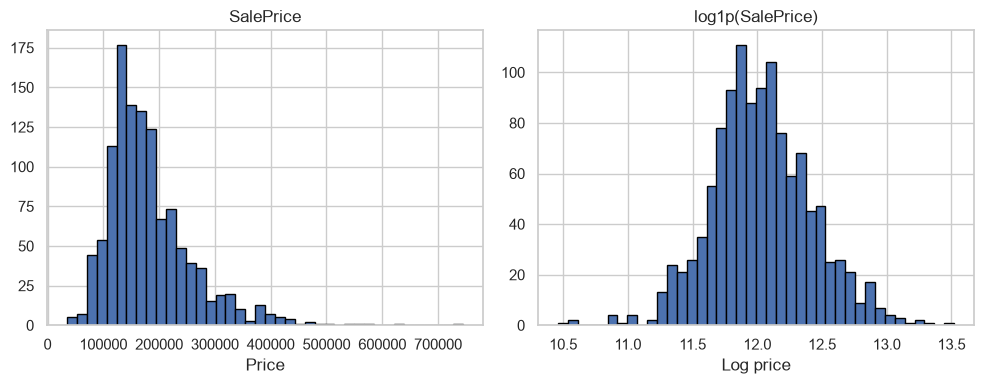

In [231]:
# Keep the original prices and make separate log targets
# log1p(x) means log(1 + x), and expm1 converts back afterwards
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(y_train, bins=40, edgecolor="black")
axes[0].set_title("SalePrice")
axes[0].set_xlabel("Price")
axes[1].hist(y_train_log, bins=40, edgecolor="black")
axes[1].set_title("log1p(SalePrice)")
axes[1].set_xlabel("Log price")
plt.tight_layout()
plt.show()


The expensive houses make a long right tail in the original prices. After the log, that tail is less extreme, the distribution is closer to normal. This should make relative price differences easier for a linear model to describe.

In [232]:
# Only change these area features, keeping all other encoded columns as they are
log_feature_cols = ["LotArea", "GrLivArea", "1stFlrSF"]
X_train_log = X_train_encoded.copy()
X_val_log = X_val_encoded.copy()

X_train_log[log_feature_cols] = np.log1p(X_train_encoded[log_feature_cols])
X_val_log[log_feature_cols] = np.log1p(X_val_encoded[log_feature_cols])

# Compare one of the features
area_comparison = pd.DataFrame({
    "GrLivArea": X_train_encoded["GrLivArea"],
    "log1p(GrLivArea)": X_train_log["GrLivArea"],
    "SalePrice": y_train,
    "log1p(SalePrice)": y_train_log,
})
area_comparison.head()

,GrLivArea,log1p(GrLivArea),SalePrice,log1p(SalePrice)
254,1314,7.181592,145000,11.884496
1066,1571,7.360104,178000,12.089544
638,796,6.680855,85000,11.350418
799,1768,7.478170,175000,12.072547
380,1691,7.433667,127000,11.751950


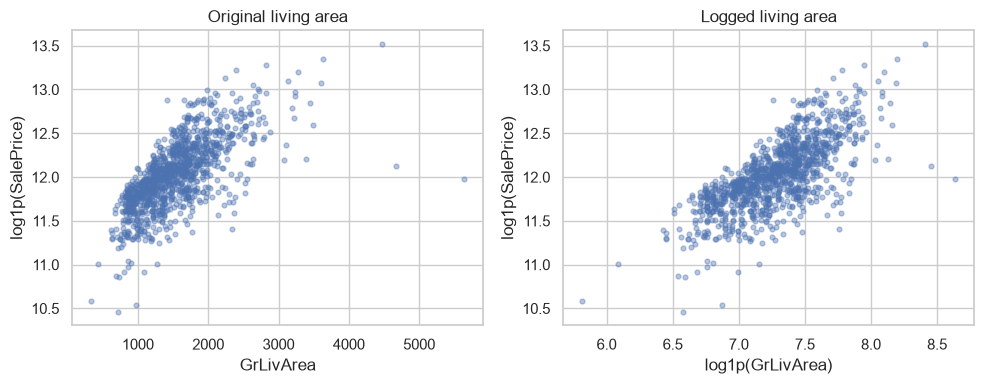

In [233]:
# Does living area have a clearer relationship with the log target?
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(X_train_encoded["GrLivArea"], y_train_log, alpha=0.4, s=12)
axes[0].set_xlabel("GrLivArea")
axes[0].set_ylabel("log1p(SalePrice)")
axes[0].set_title("Original living area")
axes[1].scatter(X_train_log["GrLivArea"], y_train_log, alpha=0.4, s=12)
axes[1].set_xlabel("log1p(GrLivArea)")
axes[1].set_ylabel("log1p(SalePrice)")
axes[1].set_title("Logged living area")
plt.tight_layout()
plt.show()


The log spreads out the smaller living areas and compresses the larger ones. The main group looks closer to a straight-line relationship with log price, which is useful to try for a linear model. The unusually large houses with low prices are still there: taking a log doesn't remove outliers completely, but now such won't skew a line for a prediction as much.

For now, I'll leave basement and garage area on their original scales because the zeros represent absence and the log makes their distributions strongly left-skewed. I'll also leave rare features like PoolArea. These are starting choices based on the exploration, not a claim that every alternative would perform worse.

In [ ]:
print("Logged predictors:", log_feature_cols)
print("Training / validation shapes:", X_train_log.shape, "/", X_val_log.shape)
print("Remaining NaN cells:", int(X_train_log.isna().sum().sum()), "|", int(X_val_log.isna().sum().sum()))

# another bunch of asserts to make sure everything runs smoothly to be able to catch mistakes early (there were some)
assert X_train_log.columns.equals(X_val_log.columns)
assert np.isfinite(X_train_log.to_numpy()).all()
assert np.isfinite(X_val_log.to_numpy()).all()
assert np.allclose(np.expm1(y_train_log), y_train)
assert np.allclose(np.expm1(y_val_log), y_val)


Logged predictors: ['LotArea', 'GrLivArea', '1stFlrSF']
Training / validation shapes: (1168, 267) / (292, 267)
Remaining NaN cells: 0 | 0


X_train_log and X_val_log contain the logged areas; y_train_log and y_val_log contain the logged prices. The original tables and targets are still available. Years, quality ratings, flags and one-hot columns haven't changed. There is no scaling or model training in this step.


4. Feature engineering

I'll add a few features that combine information already in the data: age at sale, total size, bathrooms and whether certain amenities are present. These don't use SalePrice or any statistics from other houses, so the same calculations can be applied to training and validation.

The calculations need the original units. For example, adding logged floor areas would not give a total area. I'll calculate the new features from the filled X_train and X_val, then add them to copies of X_train_log and X_val_log.

| Feature | Meaning |
|---|---|
| HouseAge | Year sold minus year built |
| YearsSinceRemodel | Year sold minus year remodelled |
| GarageAge | Year sold minus garage year, or 0 when there is no garage |
| TotalSF | Basement + first-floor + second-floor area |
| TotalBathrooms | Full bathrooms + half of the half-bathroom count, including basement bathrooms |
| TotalPorchSF | Open, enclosed, three-season and screened porch areas combined |
| HasBasement, HasFireplace, HasPool | 1 if present, otherwise 0 |
| QualityLivingArea | OverallQual multiplied by original GrLivArea |

HasGarage is already there, so I won't add it again. TotalSF doesn't add GrLivArea on top of the floor areas, since that would count living space twice. WoodDeckSF stays separate from the porch total.


In [235]:
def engineer_features(df): # use the filled features, before any area logs
    out = df.copy()

    # Age at the time of sale, rather than the construction year alone
    out["HouseAge"] = (out["YrSold"] - out["YearBuilt"]).clip(lower=0)
    out["YearsSinceRemodel"] = (out["YrSold"] - out["YearRemodAdd"]).clip(lower=0)
    out["GarageAge"] = (out["YrSold"] - out["GarageYrBlt"]).clip(lower=0)
    out.loc[out["HasGarage"] == 0, "GarageAge"] = 0

    # Combine sizes without counting the same floor area twice
    out["TotalSF"] = out["TotalBsmtSF"] + out["1stFlrSF"] + out["2ndFlrSF"]
    out["TotalBathrooms"] = (
        out["FullBath"] + out["BsmtFullBath"]
        + 0.5 * (out["HalfBath"] + out["BsmtHalfBath"])
    )
    out["TotalPorchSF"] = (
        out["OpenPorchSF"] + out["EnclosedPorch"]
        + out["3SsnPorch"] + out["ScreenPorch"]
    )

    # Separate having an amenity from how large or good it is
    out["HasBasement"] = (out["TotalBsmtSF"] > 0).astype(int)
    out["HasFireplace"] = (out["Fireplaces"] > 0).astype(int)
    out["HasPool"] = (out["PoolArea"] > 0).astype(int)

    # Let the effect of living area depend on the overall quality
    out["QualityLivingArea"] = out["OverallQual"] * out["GrLivArea"]

    return out


TotalSF and TotalBathrooms give a model a combined measure without having to learn the sum itself. Treating a half bathroom as 0.5 is a starting convention, not a claim that it adds exactly half the value. QualityLivingArea lets a linear model give size a different effect at different quality levels.

A recorded remodel or garage year can be later than the sale year. I'll use clip(lower=0) to treat a negative age as 0 for now; this is a practical assumption about inconsistent years, not a correction of the original record. GarageAge is also 0 for an absent garage, with HasGarage keeping that separate from a new garage. If a garage year was imputed with YearBuilt, its age is still only an estimate.


In [236]:
engineered_cols = [
    "HouseAge", "YearsSinceRemodel", "GarageAge", "TotalSF", "TotalBathrooms",
    "TotalPorchSF", "HasBasement", "HasFireplace", "HasPool", "QualityLivingArea",
]

# Calculate in original units, then keep only the new columns
train_engineered = engineer_features(X_train)
val_engineered = engineer_features(X_val)

X_train_features = X_train_log.copy()
X_val_features = X_val_log.copy()
X_train_features[engineered_cols] = train_engineered[engineered_cols]
X_val_features[engineered_cols] = val_engineered[engineered_cols]

print("Added features:", engineered_cols)
print("Training / validation shapes:", X_train_features.shape, "/", X_val_features.shape)
print("Remaining NaN cells:", int(X_train_features.isna().sum().sum()), "|", int(X_val_features.isna().sum().sum()))

assert X_train_features.columns.equals(X_val_features.columns)
assert X_train_features.columns.is_unique
assert X_train_features.index.equals(y_train_log.index)
assert X_val_features.index.equals(y_val_log.index)
assert np.isfinite(X_train_features.to_numpy()).all()
assert np.isfinite(X_val_features.to_numpy()).all()

# Existing encoded and logged predictors should stay unchanged
assert X_train_features[X_train_log.columns].equals(X_train_log)
assert X_val_features[X_val_log.columns].equals(X_val_log)

X_train_features[engineered_cols].head()


Added features: ['HouseAge', 'YearsSinceRemodel', 'GarageAge', 'TotalSF', 'TotalBathrooms', 'TotalPorchSF', 'HasBasement', 'HasFireplace', 'HasPool', 'QualityLivingArea']
Training / validation shapes: (1168, 277) / (292, 277)
Remaining NaN cells: 0 | 0


,HouseAge,YearsSinceRemodel,GarageAge,TotalSF,TotalBathrooms,TotalPorchSF,HasBasement,HasFireplace,HasPool,QualityLivingArea
254,53,53,53.0,2628,2.0,0,1,0,0,6570
1066,16,15,16.0,2370,2.5,40,1,1,0,9426
638,98,58,0.0,1592,1.0,164,1,0,0,3980
799,70,57,68.0,2499,2.5,264,1,1,0,8840
380,86,60,86.0,2717,2.0,242,1,1,0,8455


In [237]:
# A first look at the new features, using training rows only
feature_correlations = X_train_features[engineered_cols].corrwith(y_train_log)
feature_correlations.sort_values(ascending=False).round(3)


QualityLivingArea    0.787
TotalSF              0.762
TotalBathrooms       0.659
HasFireplace         0.507
HasBasement          0.208
TotalPorchSF         0.181
HasPool              0.084
GarageAge           -0.378
YearsSinceRemodel   -0.564
HouseAge            -0.577
dtype: float64

The correlations show the individual relationships with log price, but don't tell me whether a new feature brings something beyond the original columns. Some totals and flags repeat information that is already there. I'll keep these as candidates and check their contribution once there is a model, rather than assuming every addition helps.

5. First model comparison

I'll use four scores instead: training R², validation R², training RMSE and validation RMSE to compare different models on different datasets. Both scores will use log prices so all versions are compared on the same scale, even when a model trains on the original prices. Higher R² and lower RMSE are better. R² isn't a percentage of correct predictions, and it can be negative if the model is worse than predicting the mean log price.

I'll compare a mean-price baseline, linear regression, Ridge, a decision tree and a random forest. The tree and forest are the regression versions of the classifiers from class. Ridge is a linear model with a penalty on large coefficients. Its alpha is fixed here, with no parameter search.

Raw and filled tables still contain text, so they need basic one-hot encoding before these models can use them. The raw version also needs basic imputation. I'll keep these as simple reference versions, fitted on training rows only. All versions use the same split.

In [238]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# Raw baseline: simple median/mode fills, with every text feature one-hot encoded
# MSSubClass is a category even though it is still numeric in the raw table
raw_cat_cols = X_train_raw.select_dtypes(include="object").columns.tolist() + ["MSSubClass"]
raw_num_cols = [col for col in X_train_raw.columns if col not in raw_cat_cols]

raw_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), raw_num_cols),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), raw_cat_cols),
])

X_train_basic = raw_preprocessor.fit_transform(X_train_raw)
X_val_basic = raw_preprocessor.transform(X_val_raw)

# Filled baseline: our domain-specific fills, but no ordinal quality mappings
filled_cat_cols = X_train.select_dtypes(include="object").columns.tolist()
filled_num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
filled_preprocessor = ColumnTransformer([
    ("numeric", "passthrough", filled_num_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), filled_cat_cols),
])

X_train_filled_numeric = filled_preprocessor.fit_transform(X_train)
X_val_filled_numeric = filled_preprocessor.transform(X_val)

The first three versions train on original prices. The logged and engineered versions train on log1p prices. I'll also include encoded predictors with a log target only, to separate the effect of logging the target from logging the three area features.

Linear regression and Ridge use StandardScaler, fitted inside their training pipeline. Trees and the forest use the unscaled features. Scaling doesn't overwrite any of the X tables. The forest uses 100 trees and at least two training rows per leaf as an initial setting; these are not tuned values.


In [239]:
# Each entry contains training features, validation features and whether to log the target
training_versions = {
    "1. Raw + basic preprocessing": (X_train_basic, X_val_basic, False),
    "2. Filled + one-hot": (X_train_filled_numeric, X_val_filled_numeric, False),
    "3. Encoded": (X_train_encoded, X_val_encoded, False),
    "4. Encoded + log target": (X_train_encoded, X_val_encoded, True),
    "5. Logged": (X_train_log, X_val_log, True),
    "6. Engineered": (X_train_features, X_val_features, True),
}

results = []
trained_models = {}

for version, (train_data, val_data, log_target) in training_versions.items():
    # Create fresh models for each version, like the comparison in Homework 3
    models = {
        "Mean baseline": DummyRegressor(strategy="mean"),
        "Linear regression": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LinearRegression()),
        ]),
        "Ridge": Pipeline([
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=10)),
        ]),
        "Decision tree": DecisionTreeRegressor(random_state=42),
        "Random forest": RandomForestRegressor(
            n_estimators=100, min_samples_leaf=2, random_state=42, n_jobs=1,
        ),
    }
    target = y_train_log if log_target else y_train

    for name, model in models.items():
        model.fit(train_data, target)
        train_predictions = model.predict(train_data)
        val_predictions = model.predict(val_data)

        # Bring log-target predictions back to prices before using a common score
        if log_target:
            train_predictions = np.expm1(train_predictions)
            val_predictions = np.expm1(val_predictions)

        # Logs need positive prices; count predictions needing this safeguard
        clipped_count = int((train_predictions < 1).sum() + (val_predictions < 1).sum())
        train_pred_log = np.log(np.maximum(train_predictions, 1))
        val_pred_log = np.log(np.maximum(val_predictions, 1))

        results.append({
            "Version": version,
            "Model": name,
            "Train R2": r2_score(np.log(y_train), train_pred_log),
            "Validation R2": r2_score(np.log(y_val), val_pred_log),
            "Train log RMSE": np.sqrt(mean_squared_error(np.log(y_train), train_pred_log)),
            "Validation log RMSE": np.sqrt(mean_squared_error(np.log(y_val), val_pred_log)),
            "Clipped predictions": clipped_count,
        })
        trained_models[(version, name)] = model

    print("Finished:", version)

model_results = pd.DataFrame(results)
model_results.to_csv("model_results.csv", index=False)
model_results.sort_values("Validation log RMSE").round(4)


Finished: 1. Raw + basic preprocessing
Finished: 2. Filled + one-hot
Finished: 3. Encoded
Finished: 4. Encoded + log target
Finished: 5. Logged
Finished: 6. Engineered


,Version,Model,Train R2,Validation R2,Train log RMSE,Validation log RMSE,Clipped predictions
22,5. Logged,Ridge,0.9468,0.9224,0.0900,0.1204,0
27,6. Engineered,Ridge,0.9469,0.9220,0.0900,0.1207,0
21,5. Logged,Linear regression,0.9470,0.9214,0.0899,0.1211,0
26,6. Engineered,Linear regression,0.9520,0.9209,0.0855,0.1215,0
17,4. Encoded + log target,Ridge,0.9435,0.9187,0.0928,0.1232,0
16,4. Encoded + log target,Linear regression,0.9436,0.9180,0.0927,0.1237,0
29,6. Engineered,Random forest,0.9747,0.8893,0.0622,0.1437,0
24,5. Logged,Random forest,0.9729,0.8864,0.0642,0.1456,0
19,4. Encoded + log target,Random forest,0.9729,0.8862,0.0643,0.1457,0
14,3. Encoded,Random forest,0.9686,0.8758,0.0692,0.1523,0


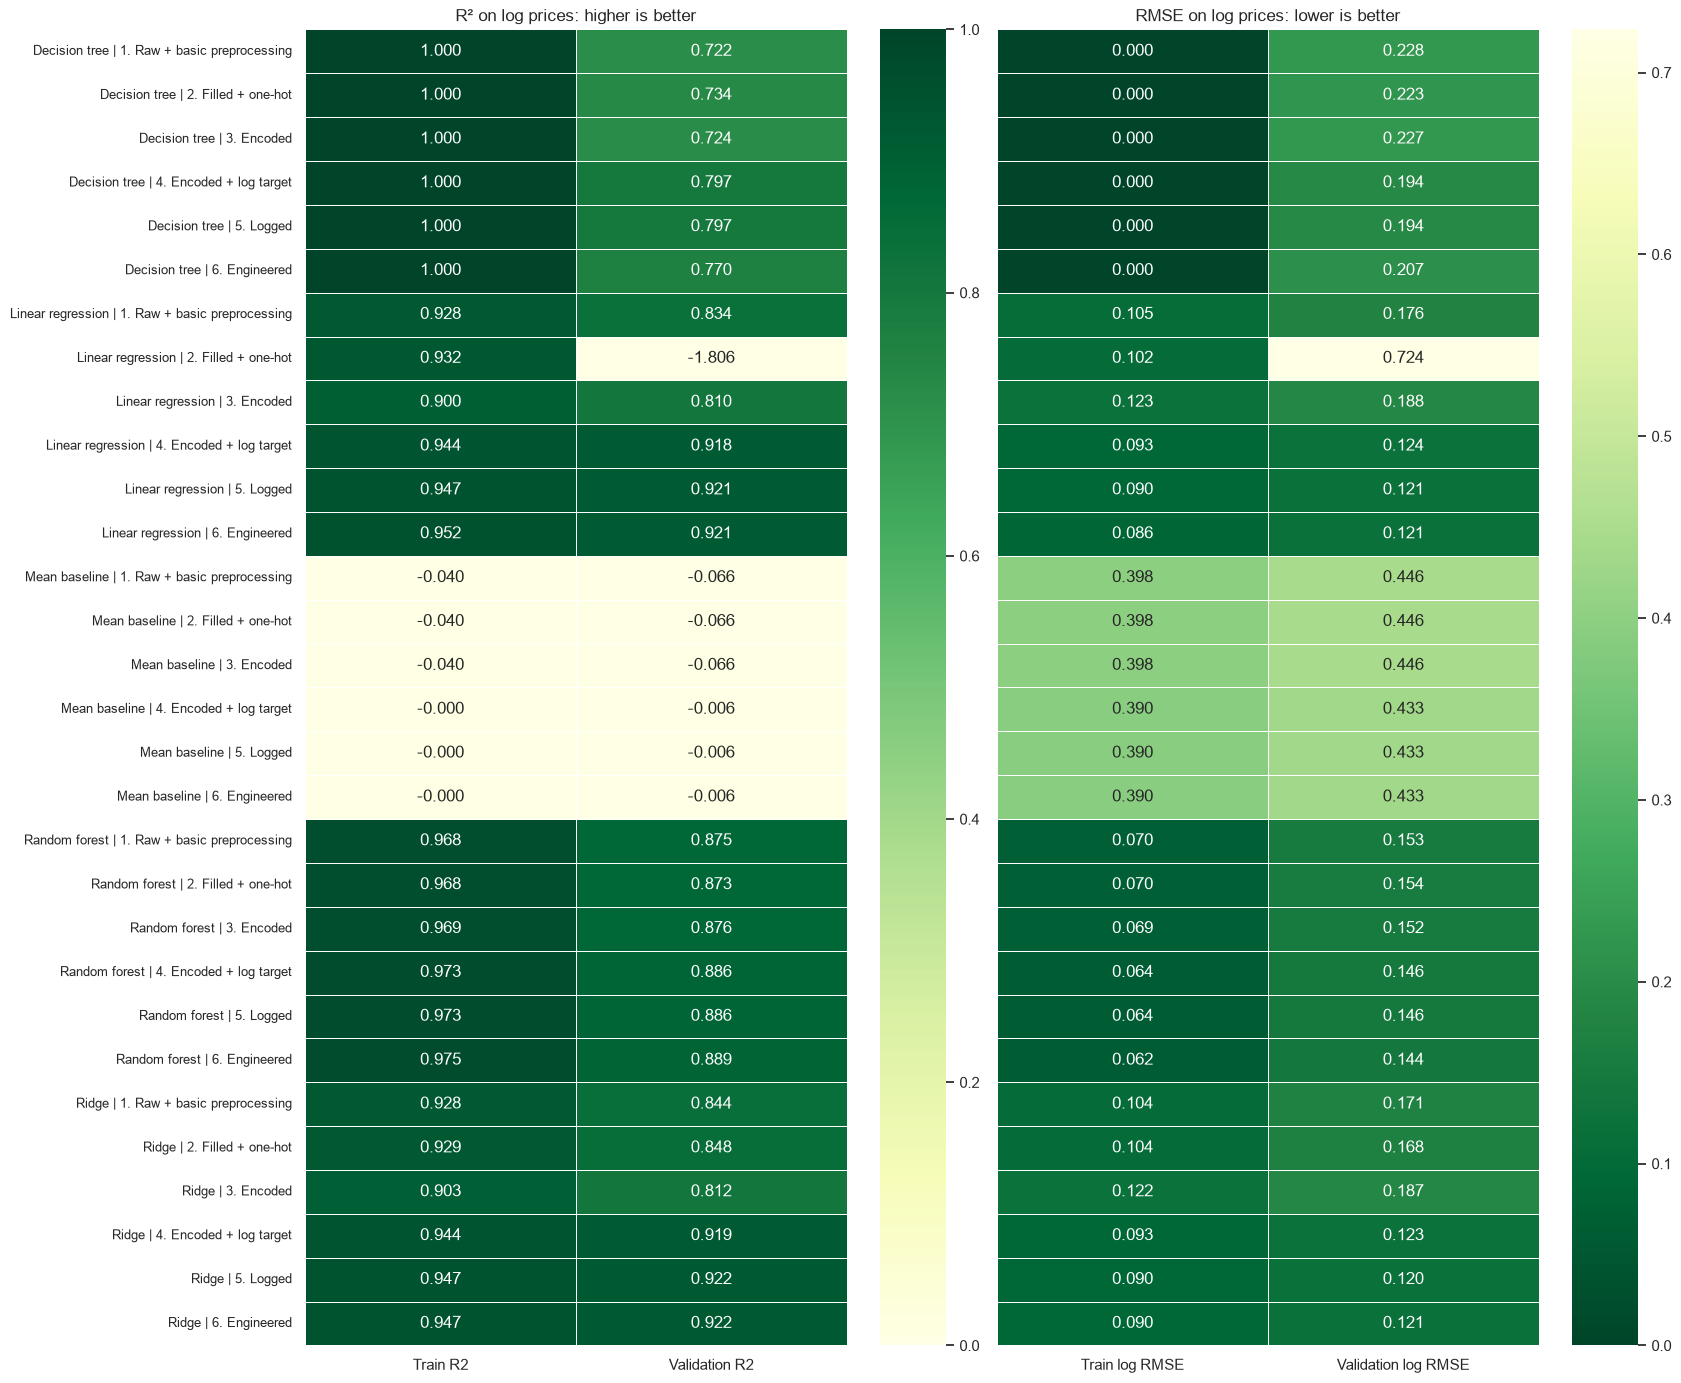

In [240]:
# Four cells per model/version, split into panels because the metrics have different scales
heatmap_results = model_results.sort_values(["Model", "Version"]).copy()
heatmap_results["Run"] = heatmap_results["Model"] + " | " + heatmap_results["Version"]
heatmap_results = heatmap_results.set_index("Run")

fig, axes = plt.subplots(1, 2, figsize=(17, 14))
sns.heatmap(
    heatmap_results[["Train R2", "Validation R2"]],
    annot=True, fmt=".3f", cmap="YlGn", vmin=0, vmax=1,
    linewidths=0.5, ax=axes[0],
)
sns.heatmap(
    heatmap_results[["Train log RMSE", "Validation log RMSE"]],
    annot=True, fmt=".3f", cmap="YlGn_r", vmin=0,
    linewidths=0.5, yticklabels=False, ax=axes[1],
)
axes[0].set_title("R² on log prices: higher is better")
axes[1].set_title("RMSE on log prices: lower is better")
axes[0].set_ylabel("")
axes[1].set_ylabel("")
axes[0].tick_params(axis="y", labelsize=9)
plt.tight_layout()
plt.savefig("model_comparison_heatmap.png", dpi=140, bbox_inches="tight")
plt.show()


The heatmap contains four scores for each model/version. Darker green means better within each panel. A large training/validation gap suggests overfitting; the validation RMSE is the main comparison for the competition: it is harsh on outliers, so the examples with log applied can perform better.

This is a first comparison on one validation split, not a final ranking proven on unseen data. I'll leave the Kaggle test file out of training and evaluation. However, this will be used for the first submission on Kaggle

On this split, Ridge with the logged features has the lowest validation log RMSE, 0.12, and validation R² of 0.9224. Adding the engineered features gives Ridge pretty much the same score, so there is no improvement for that model here. The forest improves slightly with engineering, from 0.146 to 0.144.

The unrestricted tree fits training almost perfectly, but its validation error is much higher: a clear training/validation gap, signalling overfitting. 

6. Grid search on version 6

I'll take Linear Regression, Ridge and Random Forest with the engineered features and define a parameter grid, run a cross-validation search and keep best_estimator_. The search is GridSearchCV, so every combination in each small grid is checked.

The search uses five shuffled folds from the training portion only. I can't pass X_train_features straight into CV, because its imputation and encoding were already fitted using all training rows. Instead, I'll recreate version 6 inside a pipeline so each fold learns its own replacements, one-hot categories and scaling. The quality orders and feature formulas stay fixed.

The small transformer below follows the fit/transform pattern from the Week 1 pipeline example: fit learns the imputation statistics; transform applies them, adds the same engineered features and takes the three area logs. It doesn't learn anything from the target. The encoder passes the new engineered columns through as numerical features.


In [241]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import GridSearchCV, KFold


class HouseFeatures(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.imputation_stats_ = fit_imputation(X)
        return self

    def transform(self, X):
        out = apply_imputation(X, self.imputation_stats_)
        out = engineer_features(out)
        out[log_feature_cols] = np.log1p(out[log_feature_cols])
        return out


def make_tuning_pipeline(model, scale=False):
    return Pipeline([
        ("features", HouseFeatures()),
        ("encoder", clone(encoder).set_params(remainder="passthrough")),
        ("scaler", StandardScaler() if scale else "passthrough"),
        ("model", model),
    ])


# Confirm this recreates the same version 6 values before starting the search
version6_check = make_tuning_pipeline(LinearRegression())
check_features = version6_check[:-1].fit_transform(X_train_raw)
assert set(check_features.columns) == set(X_train_features.columns)
assert np.allclose(check_features[X_train_features.columns], X_train_features)


Linear Regression only gets fit_intercept=True/False; it doesn't have a regularization strength to search. Ridge gets several alpha values, where larger alpha means stronger regularization. For the forest I'll vary the number of trees, maximum depth, minimum leaf size and fraction of candidate features at each split. The grids include the earlier alpha=10 and forest settings.

All models train on y_train_log. GridSearchCV maximizes a score, so I'll use neg_root_mean_squared_error and change its sign when displaying results. CV scores are RMSE on log1p prices; the validation metrics will use exact log prices as in the earlier comparison. The two scales differ only slightly for these prices, but I'll label them separately.


In [242]:
cv_tuning = KFold(n_splits=5, shuffle=True, random_state=42)

linear_grid = {
    "model__fit_intercept": [True, False],
}
ridge_grid = {
    "model__alpha": [0.1, 1, 10, 30, 100, 300, 1000],
}
forest_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 12],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.5, 1.0],
}

# Each search gets a fresh pipeline; validation is not passed to fit
searches = {
    "Linear regression": GridSearchCV(
        make_tuning_pipeline(LinearRegression(), scale=True),
        param_grid=linear_grid, scoring="neg_root_mean_squared_error",
        cv=cv_tuning, n_jobs=1, return_train_score=True, refit=True, error_score="raise",
    ),
    "Ridge": GridSearchCV(
        make_tuning_pipeline(Ridge(), scale=True),
        param_grid=ridge_grid, scoring="neg_root_mean_squared_error",
        cv=cv_tuning, n_jobs=1, return_train_score=True, refit=True, error_score="raise",
    ),
    "Random forest": GridSearchCV(
        make_tuning_pipeline(RandomForestRegressor(random_state=42, n_jobs=2)),
        param_grid=forest_grid, scoring="neg_root_mean_squared_error",
        cv=cv_tuning, n_jobs=1, return_train_score=True, refit=True, error_score="raise",
    ),
}


In [243]:
tuned_models = {}
cv_search_results = {}

for name, search in searches.items():
    search.fit(X_train_raw, y_train_log)
    tuned_models[name] = search.best_estimator_
    cv_search_results[name] = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")

    filename = "grid_search_" + name.lower().replace(" ", "_") + ".csv"
    cv_search_results[name].to_csv(filename, index=False)
    print(name)
    print("Best parameters:", search.best_params_)
    print("CV RMSE (log1p):", round(-search.best_score_, 4))
    print()


Linear regression
Best parameters: {'model__fit_intercept': True}
CV RMSE (log1p): 0.1551

Ridge
Best parameters: {'model__alpha': 300}
CV RMSE (log1p): 0.1364

Random forest
Best parameters: {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
CV RMSE (log1p): 0.1372



Each best_estimator_ has already been refitted on the whole training portion after the search. I'll now evaluate those three chosen settings on X_val_raw, using each fitted pipeline to recreate the features. The validation scores don't choose the parameters; the CV scores do. This validation split was already used to shortlist models, so it is a useful comparison rather than a completely fresh final test.


In [244]:
tuning_rows = []

for name, model in tuned_models.items():
    train_predictions = np.expm1(model.predict(X_train_raw))
    val_predictions = np.expm1(model.predict(X_val_raw))
    train_pred_log = np.log(np.maximum(train_predictions, 1))
    val_pred_log = np.log(np.maximum(val_predictions, 1))
    search = searches[name]

    tuning_rows.append({
        "Model": name,
        "Best parameters": str(search.best_params_),
        "CV log1p RMSE": -search.best_score_,
        "CV fold std": search.cv_results_["std_test_score"][search.best_index_],
        "Train R2": r2_score(np.log(y_train), train_pred_log),
        "Validation R2": r2_score(np.log(y_val), val_pred_log),
        "Train log RMSE": np.sqrt(mean_squared_error(np.log(y_train), train_pred_log)),
        "Validation log RMSE": np.sqrt(mean_squared_error(np.log(y_val), val_pred_log)),
        "Clipped predictions": int((train_predictions < 1).sum() + (val_predictions < 1).sum()),
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values("CV log1p RMSE")
tuning_results.to_csv("tuning_results.csv", index=False)
tuning_results.round(4)


,Model,Best parameters,CV log1p RMSE,CV fold std,Train R2,Validation R2,Train log RMSE,Validation log RMSE,Clipped predictions
1,Ridge,{'model__alpha': 300},0.1364,0.0260,0.9382,0.9185,0.0970,0.1233,0
2,Random forest,"{'model__max_depth': None, 'model__max_feature...",0.1372,0.0161,0.9835,0.8878,0.0502,0.1447,0
0,Linear regression,{'model__fit_intercept': True},0.1551,0.0250,0.9520,0.9209,0.0855,0.1215,0


In [245]:
# Compare with the same three untuned version 6 runs
previous_results = pd.read_csv("model_results.csv")
previous_version6 = previous_results[
    (previous_results["Version"] == "6. Engineered")
    & previous_results["Model"].isin(tuned_models)
][["Model", "Validation log RMSE"]]

before_after_tuning = previous_version6.merge(
    tuning_results[["Model", "CV log1p RMSE", "CV fold std", "Validation log RMSE"]],
    on="Model", suffixes=(" before", " after"),
)
before_after_tuning["Validation improvement"] = (
    before_after_tuning["Validation log RMSE before"]
    - before_after_tuning["Validation log RMSE after"]
)
before_after_tuning.to_csv("tuning_comparison.csv", index=False)
before_after_tuning.round(4)


,Model,Validation log RMSE before,CV log1p RMSE,CV fold std,Validation log RMSE after,Validation improvement
0,Linear regression,0.1215,0.1551,0.0250,0.1215,-0.0000
1,Ridge,0.1207,0.1364,0.0260,0.1233,-0.0026
2,Random forest,0.1437,0.1372,0.0161,0.1447,-0.0009


A positive validation improvement means the tuned model reduced validation RMSE. If it is negative, CV selected settings that didn't improve this particular split; tuning doesn't guarantee a lower validation error.

For the next step, the models in tuned_models include all preprocessing and can take the original predictor columns. They are still fitted on the training portion only. Before a Kaggle submission, I'll choose the final configuration, refit its full pipeline on all labelled houses and then predict the separate test file. No submission file is created in this step.


The search selected:

- Linear Regression: fit_intercept=True, CV RMSE 0.1551. (no change)
- Ridge: alpha=300, CV RMSE 0.1364.
- Random Forest: 200 trees, no maximum depth, min_samples_leaf=1 and max_features=0.5, CV RMSE 0.1370.

On the same folds, Ridge with the earlier alpha=10 scored 0.1481, and the earlier forest settings scored 0.1419. The search therefore improved the CV scores for both. Linear Regression keeps the intercept: removing it would force predictions near zero on the log-price scale.

Validation: Linear Regression scores 0.1215, tuned Ridge 0.1233 and tuned Random Forest 0.1441. The tuned Ridge and forest do not improve the earlier version 6 validation results. The linear model's result is effectively unchanged.

Ridge and the forest differ by only about 0.0006 in mean CV RMSE, no evidence that one is surely better. The unregularized linear model looks stronger on this validation split than in CV, suggesting that the result depends on which houses are held out.


7. First Kaggle submission (finally): tuned Ridge

I'll use the Ridge with alpha=300, selected by the grid search. This time I'll refit the entire pipeline on all labelled houses, including the earlier validation rows. Imputation, encoding and scaling are learned again from that full training data, then applied to the separate Kaggle test file.

The target stays log1p(SalePrice), so predictions need expm1 to turn them back into prices. I'll keep the original test Id order and check the output against sample_submission.csv before saving it. 

The code below uses the earlier function and encoder definitions. Alpha is written explicitly so I don't need to rerun the grid searches just to recreate the chosen configuration. 

In [246]:
# Refit the selected configuration on all labelled houses
X_full_raw = train.drop(columns=[TARGET, ID_COL])
y_full_log = np.log1p(train[TARGET])
X_test_raw = test.drop(columns=[ID_COL])

assert X_full_raw.columns.equals(X_test_raw.columns)

final_ridge = make_tuning_pipeline(Ridge(alpha=300), scale=True)
final_ridge.fit(X_full_raw, y_full_log)

# The fitted pipeline applies the same version 6 preprocessing to test
submission_predictions = np.expm1(final_ridge.predict(X_test_raw))
assert np.isfinite(submission_predictions).all()
assert (submission_predictions > 0).all()


In [247]:
# Match Kaggle's required columns and preserve the test row order
submission = pd.DataFrame({
    ID_COL: test[ID_COL],
    TARGET: submission_predictions,
})
sample_submission = pd.read_csv("sample_submission.csv")

assert submission.columns.equals(sample_submission.columns)
assert submission.shape == sample_submission.shape
assert submission[ID_COL].equals(sample_submission[ID_COL])
assert submission[ID_COL].is_unique
assert not submission.isna().any().any()

submission.to_csv("submission.csv", index=False)
print("Saved submission.csv:", submission.shape)
print(submission[TARGET].describe())
submission.head()


Saved submission.csv: (1459, 2)
count      1459.000000
mean     177908.932518
std       77762.700244
min       39337.939839
25%      126202.847472
50%      157892.556778
75%      211045.540603
max      983302.838144
Name: SalePrice, dtype: float64


,Id,SalePrice
0,1461,120919.019429
1,1462,159002.176343
2,1463,181895.100738
3,1464,198257.694160
4,1465,196134.492946


8. Second Kaggle submission: Forest

In [250]:
# Refit the tuned Forest, including the full preprocessing pipeline
final_forest = make_tuning_pipeline(
    RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=1,
        max_features=0.5,
        random_state=42,
        n_jobs=2,
    )
)

final_forest.fit(X_full_raw, y_full_log)
forest_predictions = np.expm1(final_forest.predict(X_test_raw))

assert np.isfinite(forest_predictions).all()
assert (forest_predictions > 0).all()

submission2 = pd.DataFrame({
    ID_COL: test[ID_COL],
    TARGET: forest_predictions,
})

assert submission2.shape == sample_submission.shape
assert submission2.columns.equals(sample_submission.columns)
assert submission2[ID_COL].equals(sample_submission[ID_COL])
assert submission2[ID_COL].is_unique
assert not submission2.isna().any().any()

submission2.to_csv("submission2.csv", index=False)
print(submission2[TARGET].describe())
submission2.head()

count      1459.000000
mean     176462.955576
std       73147.945919
min       52501.158559
25%      128157.938357
50%      154876.297148
75%      207165.983078
max      514297.962292
Name: SalePrice, dtype: float64


,Id,SalePrice
0,1461,122092.891287
1,1462,153138.951632
2,1463,176972.504991
3,1464,181653.829527
4,1465,193360.765455


9. Third Kaggle submission: Linear Regression

In [251]:
final_linear = make_tuning_pipeline(
    LinearRegression(fit_intercept=True),
    scale=True,
)

final_linear.fit(X_full_raw, y_full_log)
linear_predictions = np.expm1(final_linear.predict(X_test_raw))

assert np.isfinite(linear_predictions).all()
assert (linear_predictions > 0).all()

submission3 = pd.DataFrame({
    ID_COL: test[ID_COL],
    TARGET: linear_predictions,
})

assert submission3.shape == sample_submission.shape
assert submission3.columns.equals(sample_submission.columns)
assert submission3[ID_COL].equals(sample_submission[ID_COL])
assert submission3[ID_COL].is_unique
assert not submission3.isna().any().any()

submission3.to_csv("submission3.csv", index=False)
print(submission3[TARGET].describe())
submission3.head()

count      1459.000000
mean     177954.240688
std       78112.239009
min       37355.625082
25%      124808.581203
50%      157817.292183
75%      211208.841334
max      602715.495008
Name: SalePrice, dtype: float64


,Id,SalePrice
0,1461,120056.521541
1,1462,176483.942188
2,1463,185040.619096
3,1464,200540.815142
4,1465,197564.184395
